# Lab Problem 3 B: Coronary Heart Disease (CHD) Prediction

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, precision_score, recall_score

pd.set_option("display.float_format", lambda v: f"{v: .4f}")

In [2]:
def fit_logistic(X, y, feature_names, max_iter=100, tol=1e-10):
    n, p = X.shape
    Xd = np.column_stack([np.ones(n), X])           # design matrix w/ intercept
    names = ["Intercept"] + list(feature_names)
    beta = np.zeros(Xd.shape[1])
    for _ in range(max_iter):
        eta = Xd @ beta
        mu = 1.0 / (1.0 + np.exp(-eta))
        W = np.clip(mu * (1 - mu), 1e-10, None)
        grad = Xd.T @ (y - mu)
        H = Xd.T @ (Xd * W[:, None])                 # Fisher information matrix
        step = np.linalg.solve(H, grad)
        beta_new = beta + step
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new
            break
        beta = beta_new

    eta = Xd @ beta
    mu = 1.0 / (1.0 + np.exp(-eta))
    W = np.clip(mu * (1 - mu), 1e-10, None)
    H = Xd.T @ (Xd * W[:, None])
    cov = np.linalg.inv(H)
    se = np.sqrt(np.diag(cov))
    z = beta / se
    pvals = 2 * (1 - stats.norm.cdf(np.abs(z)))

    summary = pd.DataFrame({"coef": beta, "std_err": se, "z": z, "P>|z|": pvals}, index=names)
    return summary, mu

In [3]:
print("=" * 70)
print("TASK 1: Full logistic regression model")
print("=" * 70)

df = pd.read_csv("SAheart.csv").drop(columns=["csvbase_row_id"])
df["famhist"] = (df["famhist"] == "Present").astype(int)   # encode categorical

predictors_all = [c for c in df.columns if c != "chd"]
X_all = df[predictors_all].astype(float).values
y = df["chd"].astype(float).values

print(f"n = {df.shape[0]} patients, {len(predictors_all)} predictors")
print(f"CHD prevalence: {y.mean():.3f}\n")

summary_full, mu_full = fit_logistic(X_all, y, predictors_all)
print(summary_full, "\n")

TASK 1: Full logistic regression model
n = 462 patients, 9 predictors
CHD prevalence: 0.346

             coef  std_err       z   P>|z|
Intercept -6.1507   1.3083 -4.7015  0.0000
sbp        0.0065   0.0057  1.1350  0.2564
tobacco    0.0794   0.0266  2.9838  0.0028
ldl        0.1739   0.0597  2.9152  0.0036
adiposity  0.0186   0.0293  0.6346  0.5257
famhist    0.9254   0.2279  4.0605  0.0000
typea      0.0396   0.0123  3.2138  0.0013
obesity   -0.0629   0.0442 -1.4218  0.1551
alcohol    0.0001   0.0045  0.0271  0.9784
age        0.0452   0.0121  3.7285  0.0002 



In [4]:
print("=" * 70)
print("TASK 2: Significant predictors & reduced model")
print("=" * 70)

ALPHA = 0.05
sig_predictors = summary_full.drop("Intercept").loc[
    summary_full.drop("Intercept")["P>|z|"] < ALPHA
].index.tolist()
print(f"Significant predictors (p < {ALPHA}): {sig_predictors}\n")

X_reduced = df[sig_predictors].astype(float).values
summary_reduced, mu_reduced = fit_logistic(X_reduced, y, sig_predictors)
print(summary_reduced, "\n")

TASK 2: Significant predictors & reduced model
Significant predictors (p < 0.05): ['tobacco', 'ldl', 'famhist', 'typea', 'age']

             coef  std_err       z   P>|z|
Intercept -6.4464   0.9209 -7.0004  0.0000
tobacco    0.0804   0.0259  3.1057  0.0019
ldl        0.1620   0.0550  2.9470  0.0032
famhist    0.9082   0.2258  4.0228  0.0001
typea      0.0371   0.0122  3.0505  0.0023
age        0.0505   0.0102  4.9442  0.0000 



In [5]:
print("=" * 70)
print("TASK 3: Direction of effect (increase / decrease CHD probability)")
print("=" * 70)

coef_no_int = summary_reduced.drop("Intercept")["coef"]
odds_ratio = np.exp(coef_no_int)
effect = np.where(coef_no_int > 0, "INCREASES P(chd=1)", "DECREASES P(chd=1)")
effect_table = pd.DataFrame({"coef": coef_no_int, "odds_ratio": odds_ratio, "effect": effect})
print(effect_table, "\n")

increasers = effect_table.index[effect_table["coef"] > 0].tolist()
decreasers = effect_table.index[effect_table["coef"] < 0].tolist()
print("Increase CHD probability:", increasers)
print("Decrease CHD probability:", decreasers if decreasers else "None\n")

TASK 3: Direction of effect (increase / decrease CHD probability)
           coef  odds_ratio              effect
tobacco  0.0804      1.0837  INCREASES P(chd=1)
ldl      0.1620      1.1759  INCREASES P(chd=1)
famhist  0.9082      2.4798  INCREASES P(chd=1)
typea    0.0371      1.0378  INCREASES P(chd=1)
age      0.0505      1.0518  INCREASES P(chd=1) 

Increase CHD probability: ['tobacco', 'ldl', 'famhist', 'typea', 'age']
Decrease CHD probability: None



In [6]:
print("=" * 70)
print("TASK 4: Cut-off probability selection")
print("=" * 70)

fpr, tpr, thresholds = roc_curve(y, mu_reduced)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
cutoff = round(float(thresholds[best_idx]), 2)

print(f"AUC: {roc_auc_score(y, mu_reduced):.4f}")
print(f"Optimal cutoff (Youden's J = TPR - FPR, maximized): {thresholds[best_idx]:.4f}")
print(f"  Sensitivity at this cutoff: {tpr[best_idx]:.4f}")
print(f"  Specificity at this cutoff: {1 - fpr[best_idx]:.4f}")
print(f"Chosen cut-off for classification: {cutoff}")
print("(Close to the sample CHD prevalence of "
      f"{y.mean():.3f}, which makes sense: with an imbalanced outcome, "
      "a 0.5 cutoff is too conservative and misses too many true CHD cases.)\n")

TASK 4: Cut-off probability selection
AUC: 0.7922
Optimal cutoff (Youden's J = TPR - FPR, maximized): 0.2844
  Sensitivity at this cutoff: 0.8313
  Specificity at this cutoff: 0.6291
Chosen cut-off for classification: 0.28
(Close to the sample CHD prevalence of 0.346, which makes sense: with an imbalanced outcome, a 0.5 cutoff is too conservative and misses too many true CHD cases.)



TASK 5: Confusion matrix, precision & recall
Cut-off used: 0.28
                   Pred 0  Pred 1
Actual 0 (no CHD)     187     115
Actual 1 (CHD)         27     133

TP=133  FP=115  FN=27  TN=187
Precision (chd=1): 0.5363
Recall (chd=1):    0.8313
Accuracy:          0.6926
F1-score:          0.6520


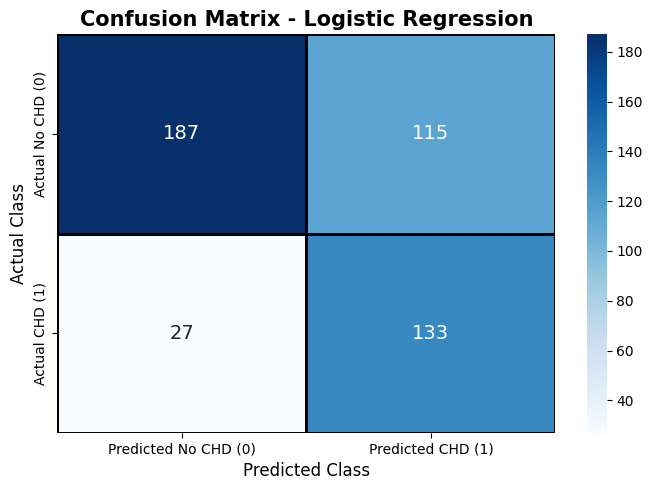

In [9]:
print("=" * 70)
print("TASK 5: Confusion matrix, precision & recall")
print("=" * 70)

y_pred = (mu_reduced >= cutoff).astype(int)
cm = confusion_matrix(y, y_pred)
tn, fp, fn, tp = cm.ravel()
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)


print(f"Cut-off used: {cutoff}")
print(pd.DataFrame(cm, index=["Actual 0 (no CHD)", "Actual 1 (CHD)"],
                        columns=["Pred 0", "Pred 1"]))
print(f"\nTP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"Precision (chd=1): {precision:.4f}")
print(f"Recall (chd=1):    {recall:.4f}")
print(f"Accuracy:          {(tp+tn)/(tp+tn+fp+fn):.4f}")
print(f"F1-score:          {2*precision*recall/(precision+recall):.4f}")

# Confusion Matrix Visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="black",
    xticklabels=["Predicted No CHD (0)", "Predicted CHD (1)"],
    yticklabels=["Actual No CHD (0)", "Actual CHD (1)"],
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - Logistic Regression", fontsize=15, fontweight="bold")
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.tight_layout()
plt.show()